# Chicago Taxi Rides: Exploratory Analysis and Hypothesis Testing

This notebook analyzes Chicago taxi ride data to understand passenger preferences and the impact of external factors on rides. It covers two questions:

1. Which neighborhoods receive the most drop-offs, and which taxi companies complete the most trips?
2. Does the average duration of rides from the Loop to O'Hare International Airport change on rainy Saturdays?

**Data**

- `1_trips_amount.csv` — number of trips per taxi company (`company_name`, `trips_amount`).
- `4_dropoff.csv` — average number of trips ending in each neighborhood (`dropoff_location_name`, `average_trips`).
- `7_loop_ohare.csv` — rides from the Loop to O'Hare International Airport, with the ride start time (`start_ts`), the weather conditions (`weather_conditions`: `Good` or `Bad`) and the ride duration in seconds (`duration_seconds`).

## Setup

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

## Load Data

In [25]:
df_trips = pd.read_csv('./datasets/1_trips_amount.csv')
df_trips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB


In [26]:
df_dropoff = pd.read_csv('./datasets/4_dropoff.csv')
df_dropoff.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB


In [29]:
df_loop_ohare = pd.read_csv('./datasets/7_loop_ohare.csv')
df_loop_ohare.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB


## Data Cleaning

- Some company names start with numeric codes (for example `0118 - 42111 Godfrey S.Awir`). A regular expression removes these leading numbers, separators and surrounding whitespace so that only the company name remains.
- `start_ts` is converted to `datetime` so that the day of the week can be extracted.

In [36]:
## Remove leading numeric codes, separators and whitespace from company names

df_trips["company_name"] = (
    df_trips["company_name"]
      .str.replace(r'^\s*\d+(?:\s*-\s*\d+)*\s*(?:-\s*)?', '', regex=True)
      .str.strip()
)

## Convert 'start_ts' to datetime
df_loop_ohare['start_ts'] = pd.to_datetime(df_loop_ohare['start_ts'])

## Top 10 Drop-off Neighborhoods

In [ ]:
top10_neighbors = df_dropoff.nlargest(10, 'average_trips')
top10_neighbors

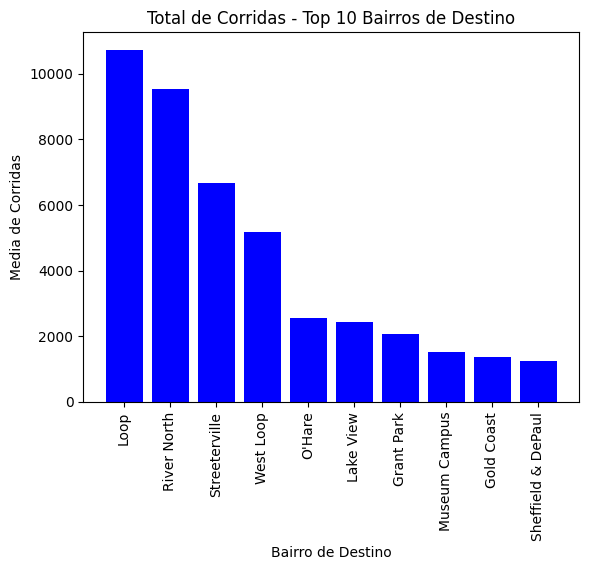

In [32]:
taxi_runs1 = plt.bar(x=top10_neighbors['dropoff_location_name'],
                    height=top10_neighbors['average_trips'],
                    color='blue')
plt.xticks(rotation=90)
plt.title('Total de Corridas - Top 10 Bairros de Destino')
plt.xlabel('Bairro de Destino')
plt.ylabel('Media de Corridas')
plt.show()

## Taxi Companies by Number of Trips

In [ ]:
top10_taxi = df_trips.nlargest(10, 'trips_amount')
top10_taxi

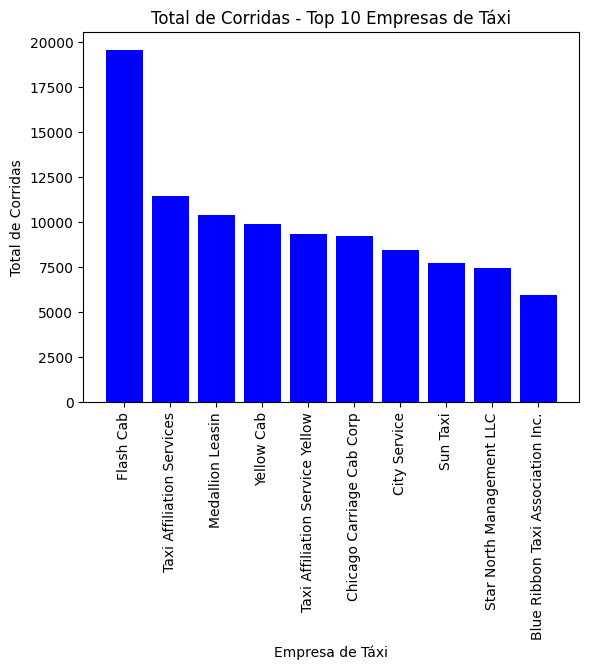

In [33]:
taxi_runs2 = plt.bar(x=top10_taxi['company_name'],
                    height=top10_taxi['trips_amount'],
                    color='blue')
plt.xticks(rotation=90)
plt.title('Total de Corridas - Top 10 Empresas de Táxi')
plt.xlabel('Empresa de Táxi')
plt.ylabel('Total de Corridas')
plt.show()

## Findings

1. Most of the top destinations are close to, or even adjacent to, one another along Chicago's lakefront in the central part of the city, where urban activity is most intense. The only neighborhood outside this cluster is O'Hare, which is expected, since Chicago's international airport is located there and shares its name.
2. Flash Cab is by far the company with the most trips, with a wide gap to the other Chicago taxi companies.

## Hypothesis Test

*"The average duration of rides from the Loop to O'Hare International Airport changes on rainy Saturdays."*

Because Saturday is a weekend day, comparing it with weekdays would not be a like-for-like comparison. The test therefore compares Saturdays with bad weather against Saturdays with good weather.

- **H₀:** the mean ride duration on rainy Saturdays (`weather_conditions == 'Bad'`) equals the mean duration on non-rainy Saturdays.
- **H₁:** the mean ride durations differ (two-tailed test, since the duration may increase or decrease).
- **Test:** Welch's two-sample t-test (`scipy.stats.ttest_ind` with `equal_var=False`), which does not assume equal variances.
- **Significance level:** α = 0.05.

In [41]:
alpha = 0.05

# Keep Saturday rides only (weekday 5)
df_loop_ohare['weekday'] = df_loop_ohare['start_ts'].dt.weekday
df_sat = df_loop_ohare[df_loop_ohare['weekday'] == 5]

rainy = df_sat[df_sat['weather_conditions'] == 'Bad']['duration_seconds']
not_rainy = df_sat[df_sat['weather_conditions'] != 'Bad']['duration_seconds']


results = st.ttest_ind(rainy, not_rainy, equal_var=False)

if results.pvalue < alpha:
    print("Rejeitamos a hipótese nula")
else:
    print("Não podemos rejeitar a hipótese nula")

Rejeitamos a hipótese nula


## Conclusion

The null hypothesis was rejected at α = 0.05: the average duration of Loop → O'Hare rides on rainy Saturdays differs from the average duration on Saturdays with good weather. In other words, the data provides statistically significant evidence that weather conditions affect the duration of this route on Saturdays.